# **Parte 1. Acondicionamiento del dataset**


Adaptacion de la tabla de datos: Tenemos diferentes tablas por años, y necesitamos unificarlas para eso hacemos lo siguiente

Celda 1. Instalar e importar librerías

In [1]:
# Si fuera necesario:
# !pip install -q openpyxl scikit-learn

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from IPython.display import display

pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", 100)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

print("Librerías cargadas correctamente.")

Librerías cargadas correctamente.


Celda 2. Cargamos el dataset completo

In [2]:
import glob
import pandas as pd

# Buscar todos los archivos CSV de EESS anuales del periodo 2018-2024
# Filtramos para excluir explícitamente cualquier archivo de salida como 'EESS_limpio.csv'
archivos_eess = sorted([
    f for f in glob.glob("/content/EESS_*.csv")
    if not f.endswith("limpio.csv")
])

print("Archivos encontrados para unificar:", archivos_eess)

# Cargar y concatenar todos los datasets anuales
lista_dfs = []
for archivo in archivos_eess:
    df_temp = pd.read_csv(archivo, low_memory=False)

    # Eliminar columnas de identificación previas si existen para evitar duplicación y confusión
    columnas_a_eliminar = [col for col in ['_id', 'id', 'id.1'] if col in df_temp.columns]
    if columnas_a_eliminar:
        df_temp = df_temp.drop(columns=columnas_a_eliminar)

    print(f"Cargado {archivo} - Filas: {df_temp.shape[0]}, Columnas restantes: {df_temp.shape[1]}")
    lista_dfs.append(df_temp)

# Crear el dataset unificado con el nombre solicitado
estaciones_de_servicio_unificado = pd.concat(lista_dfs, ignore_index=True)

# Crear una nueva columna ID incremental única que comience desde 1 hasta el total de filas
estaciones_de_servicio_unificado.insert(0, 'id', range(1, len(estaciones_de_servicio_unificado) + 1))

# Creamos una variable de referencia rápida 'df' para mantener compatibilidad
df = estaciones_de_servicio_unificado.copy()

print("\nTotal filas unificadas:", estaciones_de_servicio_unificado.shape[0])
print("Total columnas:", estaciones_de_servicio_unificado.shape[1])

display(estaciones_de_servicio_unificado.head())

Archivos encontrados para unificar: ['/content/EESS_2018.csv', '/content/EESS_2019.csv', '/content/EESS_2020.csv', '/content/EESS_2021.csv', '/content/EESS_2022.csv', '/content/EESS_2023.csv', '/content/EESS_2024.csv']
Cargado /content/EESS_2018.csv - Filas: 2250, Columnas restantes: 19
Cargado /content/EESS_2019.csv - Filas: 3500, Columnas restantes: 19
Cargado /content/EESS_2020.csv - Filas: 7750, Columnas restantes: 19
Cargado /content/EESS_2021.csv - Filas: 2250, Columnas restantes: 19
Cargado /content/EESS_2022.csv - Filas: 35000, Columnas restantes: 19
Cargado /content/EESS_2023.csv - Filas: 7500, Columnas restantes: 19
Cargado /content/EESS_2024.csv - Filas: 4250, Columnas restantes: 19

Total filas unificadas: 62500
Total columnas: 20


,id,anio,mes,operador,nro_inscripcion,bandera,fecha_de_baja,cuit,tipo_negocio,direccion,localidad,provincia,producto,canal_de_comercializacion,precio_sin_impuestos,precio_con_impuestos,volumen,precio_surtidor,no_novimientos,exentos
0,1,2018,1,10 DE SETIEMBRE S.A.,1376,BLANCA,NaN,33-64337382-9,Bocas de expendio (venta por menor) Duales (líquidos + GNC),Av. Mosconi 299,LOMAS DEL MIRADOR,BUENOS AIRES,Nafta (súper) entre 92 y 95 Ron,Al público,14.61,22.97,23.04,23.30,NO,f
1,2,2018,1,10 DE SETIEMBRE S.A.,1376,BLANCA,NaN,33-64337382-9,Bocas de expendio (venta por menor) Duales (líquidos + GNC),Av. Mosconi 299,LOMAS DEL MIRADOR,BUENOS AIRES,Nafta (premium) de más de 95 Ron,Al público,17.17,26.42,3.88,26.70,NO,f
2,3,2018,1,10 DE SETIEMBRE S.A.,1376,BLANCA,NaN,33-64337382-9,Bocas de expendio (venta por menor) Duales (líquidos + GNC),Av. Mosconi 299,LOMAS DEL MIRADOR,BUENOS AIRES,Gas Oil Grado 2,Al público,13.74,20.59,13.24,20.80,NO,f
3,4,2018,1,10 DE SETIEMBRE S.A.,1376,BLANCA,NaN,33-64337382-9,Bocas de expendio (venta por menor) Duales (líquidos + GNC),Av. Mosconi 299,LOMAS DEL MIRADOR,BUENOS AIRES,Gas Oil Grado 3,Al público,16.10,23.94,3.56,24.21,NO,f
4,5,2018,1,10 DE SETIEMBRE S.A.,1376,BLANCA,NaN,33-64337382-9,Bocas de expendio (venta por menor) Duales (líquidos + GNC),Av. Mosconi 299,LOMAS DEL MIRADOR,BUENOS AIRES,GNC,Al público,7.74,10.33,"74,921.10",10.99,NO,f


Celda 3. Trabajamos sobre una copia del dataset unificado consolidado de todos los CSV (62,500 registros)

In [3]:
df_original = estaciones_de_servicio_unificado.copy()
df = df_original.copy()

print("Cantidad de filas unificadas y consolidadas:", df.shape[0])
print("Cantidad de columnas unificadas y consolidadas:", df.shape[1])

display(df.head())

Cantidad de filas unificadas y consolidadas: 62500
Cantidad de columnas unificadas y consolidadas: 20


,id,anio,mes,operador,nro_inscripcion,bandera,fecha_de_baja,cuit,tipo_negocio,direccion,localidad,provincia,producto,canal_de_comercializacion,precio_sin_impuestos,precio_con_impuestos,volumen,precio_surtidor,no_novimientos,exentos
0,1,2018,1,10 DE SETIEMBRE S.A.,1376,BLANCA,NaN,33-64337382-9,Bocas de expendio (venta por menor) Duales (líquidos + GNC),Av. Mosconi 299,LOMAS DEL MIRADOR,BUENOS AIRES,Nafta (súper) entre 92 y 95 Ron,Al público,14.61,22.97,23.04,23.30,NO,f
1,2,2018,1,10 DE SETIEMBRE S.A.,1376,BLANCA,NaN,33-64337382-9,Bocas de expendio (venta por menor) Duales (líquidos + GNC),Av. Mosconi 299,LOMAS DEL MIRADOR,BUENOS AIRES,Nafta (premium) de más de 95 Ron,Al público,17.17,26.42,3.88,26.70,NO,f
2,3,2018,1,10 DE SETIEMBRE S.A.,1376,BLANCA,NaN,33-64337382-9,Bocas de expendio (venta por menor) Duales (líquidos + GNC),Av. Mosconi 299,LOMAS DEL MIRADOR,BUENOS AIRES,Gas Oil Grado 2,Al público,13.74,20.59,13.24,20.80,NO,f
3,4,2018,1,10 DE SETIEMBRE S.A.,1376,BLANCA,NaN,33-64337382-9,Bocas de expendio (venta por menor) Duales (líquidos + GNC),Av. Mosconi 299,LOMAS DEL MIRADOR,BUENOS AIRES,Gas Oil Grado 3,Al público,16.10,23.94,3.56,24.21,NO,f
4,5,2018,1,10 DE SETIEMBRE S.A.,1376,BLANCA,NaN,33-64337382-9,Bocas de expendio (venta por menor) Duales (líquidos + GNC),Av. Mosconi 299,LOMAS DEL MIRADOR,BUENOS AIRES,GNC,Al público,7.74,10.33,"74,921.10",10.99,NO,f


Celda 4. Normalizamos los nombres de las columnas

In [4]:
import re
import unicodedata

# Asegurar que df sea la copia exacta del dataset consolidado unificado
df = estaciones_de_servicio_unificado.copy()

def normalizar_nombre(nombre):
    nombre = str(nombre).strip().lower()
    nombre = unicodedata.normalize("NFKD", nombre)
    nombre = "".join(
        c for c in nombre
        if not unicodedata.combining(c)
    )
    nombre = re.sub(r"[^a-z0-9]+", "_", nombre)
    return nombre.strip("_")

# Normalizar solo las columnas reales existentes en el DataFrame consolidado
df.columns = [
    normalizar_nombre(col)
    for col in df.columns
]

print("Cantidad de registros consolidados:", df.shape[0])
print("Nombres de columnas normalizados para el dataset consolidado:")
print(df.columns.tolist())

Cantidad de registros consolidados: 62500
Nombres de columnas normalizados para el dataset consolidado:
['id', 'anio', 'mes', 'operador', 'nro_inscripcion', 'bandera', 'fecha_de_baja', 'cuit', 'tipo_negocio', 'direccion', 'localidad', 'provincia', 'producto', 'canal_de_comercializacion', 'precio_sin_impuestos', 'precio_con_impuestos', 'volumen', 'precio_surtidor', 'no_novimientos', 'exentos']


Como se puede observar en la salida:

Cantidad de registros procesados: 62,500 (el total unificado de todos los años).
Columnas normalizadas: Se han estandarizado los nombres de las 20 columnas a minúsculas, sin caracteres especiales ni acentos (por ejemplo, nro_inscripcion, tipo_negocio, canal_de_comercializacion, etc.).
Todo el flujo posterior del notebook queda perfectamente alineado y sincronizado con este volumen total consolidado.

Celda 5. Limpiamos espacios y cadenas vacías

In [5]:
# Vemos cuantos datos faltantes hay en cada columna (mostramos solo las que tienen)
faltantes = df.isnull().sum()
print(faltantes[faltantes > 0])

fecha_de_baja    57399
direccion            7
exentos            685
dtype: int64


Notar que **fecha de baja** tiene una gran cantidad de valores nulos, sin embargo esto no es un error debido a que son aquellas estaciones que siguen activas.

In [6]:
# Convertimos exentos (t / f) a True / False
df['exentos'] = df['exentos'].map({'t': True, 'f': False})
print(df['exentos'].value_counts(dropna=False))

exentos
False    60203
True      1612
NaN        685
Name: count, dtype: int64


In [7]:
# La columna no_novimientos (SI / NO) la pasamos a True / False con un nombre mas claro
df['sin_movimientos'] = df['no_novimientos'].map({'SI': True, 'NO': False})
print(df['sin_movimientos'].value_counts())

sin_movimientos
False    61815
True       685
Name: count, dtype: int64


Para poder verificar que esas estaciones NO estan activas, creamos la columna "**sin movimientos**" que toma el valor "True" en caso de que la entrada sea **si** en la columna **"no movimiento"**. Analizamos cuales de esas filas son "**True**" dentro de las "fecha de baja" con entrada nula para inferir que efectivamente no estan activas.

In [8]:
# fecha_de_baja: los nulos son estaciones activas, no es un error.
# exentos: vemos si los nulos coinciden con las filas "sin movimientos"
print(pd.crosstab(df['sin_movimientos'], df['exentos'].isnull()))

exentos          False  True 
sin_movimientos              
False            61815      0
True                 0    685


In [9]:
# Decidimos borrar los 685 registros que no poseen fecha de baja, ademas no tienen movimientos por lo que interpretamos que son estaciones inactivas
df = df[df['sin_movimientos'] == False].copy()
print("Cantidad de registros restantes en df:", df.shape[0])

Cantidad de registros restantes en df: 61815


In [10]:
## eliminamos los registros de: Precios sin impuestos mayores que precios con impuestos: 44
df = df[df["precio_sin_impuestos"] <= df["precio_con_impuestos"]]

In [11]:
##corremos nuevamente para verificar las filas que borramos: 44 registros y 685
print(
    "Precios sin impuestos mayores que precios con impuestos:",
    (df["precio_sin_impuestos"] >
     df["precio_con_impuestos"]).sum()
)

Precios sin impuestos mayores que precios con impuestos: 0


In [12]:
# El bloque está perfectamente ubicado aquí. Se ejecuta después de eliminar registros inactivos
# y antes de analizar los valores nulos, asegurando que las cadenas vacías se conviertan a NaN a tiempo.
columnas_texto = df.select_dtypes(
    include=["object", "string"]
).columns

for col in columnas_texto:
    df[col] = (
        df[col]
        .astype("string")
        .str.strip()
        .str.replace(r"\s+", " ", regex=True)
    )

# Convertir cadenas vacías en nulos.
df = df.replace(r"^\s*$", np.nan, regex=True)

print("Limpieza básica de textos completada.")
display(df.head())

Limpieza básica de textos completada.


,id,anio,mes,operador,nro_inscripcion,bandera,fecha_de_baja,cuit,tipo_negocio,direccion,localidad,provincia,producto,canal_de_comercializacion,precio_sin_impuestos,precio_con_impuestos,volumen,precio_surtidor,no_novimientos,exentos,sin_movimientos
0,1,2018,1,10 DE SETIEMBRE S.A.,1376,BLANCA,<NA>,33-64337382-9,Bocas de expendio (venta por menor) Duales (líquidos + GNC),Av. Mosconi 299,LOMAS DEL MIRADOR,BUENOS AIRES,Nafta (súper) entre 92 y 95 Ron,Al público,14.61,22.97,23.04,23.30,NO,False,False
1,2,2018,1,10 DE SETIEMBRE S.A.,1376,BLANCA,<NA>,33-64337382-9,Bocas de expendio (venta por menor) Duales (líquidos + GNC),Av. Mosconi 299,LOMAS DEL MIRADOR,BUENOS AIRES,Nafta (premium) de más de 95 Ron,Al público,17.17,26.42,3.88,26.70,NO,False,False
2,3,2018,1,10 DE SETIEMBRE S.A.,1376,BLANCA,<NA>,33-64337382-9,Bocas de expendio (venta por menor) Duales (líquidos + GNC),Av. Mosconi 299,LOMAS DEL MIRADOR,BUENOS AIRES,Gas Oil Grado 2,Al público,13.74,20.59,13.24,20.80,NO,False,False
3,4,2018,1,10 DE SETIEMBRE S.A.,1376,BLANCA,<NA>,33-64337382-9,Bocas de expendio (venta por menor) Duales (líquidos + GNC),Av. Mosconi 299,LOMAS DEL MIRADOR,BUENOS AIRES,Gas Oil Grado 3,Al público,16.10,23.94,3.56,24.21,NO,False,False
4,5,2018,1,10 DE SETIEMBRE S.A.,1376,BLANCA,<NA>,33-64337382-9,Bocas de expendio (venta por menor) Duales (líquidos + GNC),Av. Mosconi 299,LOMAS DEL MIRADOR,BUENOS AIRES,GNC,Al público,7.74,10.33,"74,921.10",10.99,NO,False,False


Celda 5. Revisamos los valores faltantes

In [13]:
resumen_nulos = pd.DataFrame({
    "cantidad_nulos": df.isna().sum(),
    "porcentaje_nulos": (
        df.isna().mean() * 100
    ).round(2)
}).sort_values(
    "porcentaje_nulos",
    ascending=False
)

display(resumen_nulos)

,cantidad_nulos,porcentaje_nulos
fecha_de_baja,56920,92.15
anio,0,0.00
mes,0,0.00
operador,0,0.00
id,0,0.00
nro_inscripcion,0,0.00
bandera,0,0.00
cuit,0,0.00
tipo_negocio,0,0.00
direccion,0,0.00


In [14]:
import pandas as pd
import numpy as np

# Seleccionar únicamente las columnas con tipos de datos numéricos
columnas_numericas = df.select_dtypes(include=[np.number]).columns

# Contar cuántas filas tienen exactamente el valor 0 en cada columna numérica
ceros_por_columna = (df[columnas_numericas] == 0).sum()
porcentaje_ceros = ((df[columnas_numericas] == 0).mean() * 100).round(2)

# Crear un DataFrame de resumen ordenado por cantidad de ceros de mayor a menor
resumen_ceros = pd.DataFrame({
    "cantidad_ceros": ceros_por_columna,
    "porcentaje_ceros": porcentaje_ceros
}).sort_values("cantidad_ceros", ascending=False)

display(resumen_ceros)

,cantidad_ceros,porcentaje_ceros
precio_surtidor,9332,15.11
id,0,0.00
mes,0,0.00
anio,0,0.00
nro_inscripcion,0,0.00
precio_sin_impuestos,0,0.00
precio_con_impuestos,0,0.00
volumen,0,0.00


Ahora generamos un gráfico de los porcentajes de nulos.

Celda 6. Identificamos y tratamos duplicados

In [15]:
duplicados_exactos = df.duplicated().sum()

print("Duplicados exactos:", duplicados_exactos)

# Revisar duplicados por clave candidata de negocio.
clave_candidata = [
    "nro_inscripcion",
    "anio",
    "mes",
    "producto"
]

duplicados_clave = df.duplicated(
    subset=clave_candidata,
    keep=False
).sum()

print(
    "Filas que pertenecen a combinaciones repetidas "
    "de estación, período y producto:",
    duplicados_clave
)

Duplicados exactos: 0
Filas que pertenecen a combinaciones repetidas de estación, período y producto: 10798


Como no hay duplicados exactos en el archivo, no es necesario eliminarlos. Tampoco debemos eliminar las claves de negocio repetidas: pueden representar registros válidos de la misma estación y producto.

Celda 7. Detectar valores inválidos y sospechosos

In [16]:
print(
    "Volúmenes negativos:",
    (df["volumen"] < 0).sum()
)

print(
    "Volúmenes iguales a cero:",
    (df["volumen"] == 0).sum()
)

print(
    "Años fuera del rango esperado:",
    (~df["anio"].between(2018, 2025)).sum()
)

print(
    "Meses inválidos:",
    (~df["mes"].between(1, 12)).sum()
)

print(
    "Precios sin impuestos mayores que precios con impuestos:",
    (df["precio_sin_impuestos"] >
     df["precio_con_impuestos"]).sum()
)

print(
    "Precio con impuestos distinto de precio surtidor:",
    (df["precio_con_impuestos"] !=
     df["precio_surtidor"]).sum()
)

Volúmenes negativos: 0
Volúmenes iguales a cero: 0
Años fuera del rango esperado: 0
Meses inválidos: 0
Precios sin impuestos mayores que precios con impuestos: 0
Precio con impuestos distinto de precio surtidor: 33584


Celda 8. Revisamos valores extremos sin eliminarlos

In [17]:
percentiles = df["volumen"].quantile(
    [0, 0.25, 0.50, 0.75, 0.90, 0.95, 0.99, 1]
)

display(percentiles.to_frame("volumen"))

,volumen
0.00,0.00
0.25,19.01
0.50,55.84
0.75,135.62
0.90,460.90
0.95,"72,930.65"
0.99,"144,900.60"
1.00,"1,110,980.00"


In [18]:
# Aseguramos que la columna periodo esté bien calculada en df para evitar el KeyError
if 'periodo' not in df.columns:
    df['periodo'] = df['anio'].astype(str) + '-' + df['mes'].astype(str).str.zfill(2) + '-01'

# Como ejemplo, vemos los limites (con 3 * IQR) de precio_surtidor para nafta super en enero de 2022
ejemplo = df[(df['producto'] == 'Nafta (súper) entre 92 y 95 Ron') & (df['periodo'] == '2022-01-01')]['precio_surtidor']
Q1 = ejemplo.quantile(0.25)
Q3 = ejemplo.quantile(0.75)
IQR = Q3 - Q1
print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Límite inferior:", Q1 - 3 * IQR)
print("Límite superior:", Q3 + 3 * IQR)

Q1: 93.7
Q3: 99.9
IQR: 6.200000000000003
Límite inferior: 75.1
Límite superior: 118.50000000000001


Celda 9. Creamos el dataset limpio.

Para mantener la trazabilidad, conservamos df_original y guardamos una copia de los datos normalizados.

In [19]:
df_limpio = df.copy()

print("Dimensiones originales:", df_original.shape)
print("Dimensiones después de la limpieza:", df_limpio.shape)

df_limpio.to_csv(
    "/content/EESS_limpio.csv",
    index=False,
    encoding="utf-8-sig"
)

print("Archivo limpio guardado.")

Dimensiones originales: (62500, 20)
Dimensiones después de la limpieza: (61771, 22)
Archivo limpio guardado.


# **Parte 2. Análisis exploratorio de datos (EDA)**


Celda 10. Variables cuantitativas del dataset unificado

In [20]:
# Variables cuantitativas del dataset unificado
variables_cuantitativas = ['precio_sin_impuestos', 'precio_con_impuestos', 'precio_surtidor', 'volumen']

print("=== ESTADÍSTICAS DESCRIPTIVAS DE VARIABLES CUANTITATIVAS ===")
display(estaciones_de_servicio_unificado[variables_cuantitativas].describe())

=== ESTADÍSTICAS DESCRIPTIVAS DE VARIABLES CUANTITATIVAS ===


,precio_sin_impuestos,precio_con_impuestos,precio_surtidor,volumen
count,"62,500.00","62,500.00","62,500.00","62,500.00"
mean,112.12,149.30,127.57,"7,766.20"
std,161.49,199.30,194.28,"29,455.57"
min,0.00,0.00,0.00,0.00
25%,46.19,63.90,43.99,18.07
50%,69.90,99.50,94.30,54.84
75%,86.61,119.59,114.60,134.29
max,"1,640.25","1,999.00","1,999.00","1,110,980.00"


In [21]:
# Resumen informativo del conjunto de datos
print("=== Información General del Dataset ===")
estaciones_de_servicio_unificado.info()

# Estadísticos descriptivos para variables numéricas (excluyendo id, anio, mes, nro_inscripcion)
print("\n=== Estadísticos Descriptivos (Numéricos) ===")
columnas_num_filtradas = [col for col in estaciones_de_servicio_unificado.columns if col in ['precio_sin_impuestos', 'precio_con_impuestos', 'precio_surtidor', 'volumen']]
display(estaciones_de_servicio_unificado[columnas_num_filtradas].describe())

# Estadísticos descriptivos para variables categóricas seleccionadas (respetando su orden en el dataset)
print("\n=== Estadísticos Descriptivos (Categóricos) ===")
columnas_cat_especificas = ['operador', 'bandera', 'tipo_negocio', 'localidad', 'provincia', 'producto', 'canal_de_comercializacion']
columnas_cat_filtradas = [col for col in estaciones_de_servicio_unificado.columns if col in columnas_cat_especificas]
display(estaciones_de_servicio_unificado[columnas_cat_filtradas].describe(include=['O']))

=== Información General del Dataset ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 62500 entries, 0 to 62499
Data columns (total 20 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   id                         62500 non-null  int64  
 1   anio                       62500 non-null  int64  
 2   mes                        62500 non-null  int64  
 3   operador                   62500 non-null  object 
 4   nro_inscripcion            62500 non-null  int64  
 5   bandera                    62500 non-null  object 
 6   fecha_de_baja              5101 non-null   object 
 7   cuit                       62500 non-null  object 
 8   tipo_negocio               62500 non-null  object 
 9   direccion                  62493 non-null  object 
 10  localidad                  62500 non-null  object 
 11  provincia                  62500 non-null  object 
 12  producto                   62500 non-null  object 
 13  canal_

,precio_sin_impuestos,precio_con_impuestos,volumen,precio_surtidor
count,"62,500.00","62,500.00","62,500.00","62,500.00"
mean,112.12,149.30,"7,766.20",127.57
std,161.49,199.30,"29,455.57",194.28
min,0.00,0.00,0.00,0.00
25%,46.19,63.90,18.07,43.99
50%,69.90,99.50,54.84,94.30
75%,86.61,119.59,134.29,114.60
max,"1,640.25","1,999.00","1,110,980.00","1,999.00"



=== Estadísticos Descriptivos (Categóricos) ===


,operador,bandera,tipo_negocio,localidad,provincia,producto,canal_de_comercializacion
count,62500,62500,62500,62500,62500,62500,62500
unique,4160,22,12,1161,24,10,8
top,AUTOMOVIL CLUB ARGENTINO,YPF,Bocas de expendio (venta por menor) Combustibles líquidos únicamente,CAPITAL FEDERAL,BUENOS AIRES,Gas Oil Grado 2,Al público
freq,4270,23317,36284,2208,22030,16549,52462


In [22]:
# Agrupamos por año y generamos el describe para las variables cuantitativas
for anio, group in estaciones_de_servicio_unificado.groupby('anio'):
    print(f"\n=== ESTADÍSTICAS DESCRIPTIVAS PARA EL AÑO: {anio} ===")
    display(group[variables_cuantitativas].describe())



=== ESTADÍSTICAS DESCRIPTIVAS PARA EL AÑO: 2018 ===


,precio_sin_impuestos,precio_con_impuestos,precio_surtidor,volumen
count,"2,250.00","2,250.00","2,250.00","2,250.00"
mean,15.51,23.01,20.34,"6,492.60"
std,3.17,4.95,9.98,"26,980.70"
min,0.00,0.00,0.00,0.00
25%,14.25,21.16,19.66,24.09
50%,15.88,23.46,23.84,59.36
75%,17.49,26.17,26.77,135.04
max,26.71,49.72,55.37,"290,059.00"



=== ESTADÍSTICAS DESCRIPTIVAS PARA EL AÑO: 2019 ===


,precio_sin_impuestos,precio_con_impuestos,precio_surtidor,volumen
count,"3,500.00","3,500.00","3,500.00","3,500.00"
mean,27.37,38.64,32.74,"6,750.66"
std,5.93,8.21,16.23,"27,883.12"
min,0.00,0.00,0.00,0.00
25%,25.88,36.83,31.79,17.56
50%,27.58,39.99,38.96,54.15
75%,31.39,43.99,43.80,125.09
max,46.45,55.00,55.00,"285,679.00"



=== ESTADÍSTICAS DESCRIPTIVAS PARA EL AÑO: 2020 ===


,precio_sin_impuestos,precio_con_impuestos,precio_surtidor,volumen
count,"7,750.00","7,750.00","7,750.00","7,750.00"
mean,39.59,55.71,48.10,"8,511.36"
std,9.09,12.48,22.63,"31,529.03"
min,0.00,0.00,0.00,0.00
25%,37.63,53.68,49.94,17.78
50%,40.39,58.80,57.59,54.84
75%,45.58,63.69,63.14,135.12
max,92.89,95.00,95.00,"369,767.00"


... (4 outputs left out)


=== ESTADÍSTICAS DESCRIPTIVAS PARA EL AÑO: 2023 ===


,precio_sin_impuestos,precio_con_impuestos,precio_surtidor,volumen
count,"7,500.00","7,500.00","7,500.00","7,500.00"
mean,153.75,204.07,172.92,"7,444.92"
std,43.68,55.29,92.17,"30,358.43"
min,0.00,0.00,0.00,0.00
25%,130.77,180.39,132.70,18.59
50%,155.04,206.26,196.55,57.52
75%,177.80,236.33,233.70,140.17
max,376.53,469.90,480.00,"891,980.00"



=== ESTADÍSTICAS DESCRIPTIVAS PARA EL AÑO: 2024 ===


,precio_sin_impuestos,precio_con_impuestos,precio_surtidor,volumen
count,"4,250.00","4,250.00","4,250.00","4,250.00"
mean,668.58,834.26,714.72,"6,579.31"
std,167.73,203.18,365.22,"24,626.94"
min,0.00,0.00,0.00,0.00
25%,630.66,791.10,620.00,17.96
50%,691.45,860.65,849.00,54.30
75%,782.34,970.99,978.00,135.91
max,"1,640.25","1,999.00","1,999.00","280,148.00"


In [23]:
# Calcular el promedio de ventas (volumen) por producto y bandera
promedio_ventas = estaciones_de_servicio_unificado.groupby(['producto', 'bandera'])['volumen'].mean().reset_index()

# Renombrar columna para mayor claridad
promedio_ventas = promedio_ventas.rename(columns={'volumen': 'volumen_promedio'})

# Ordenar los resultados por producto y por volumen_promedio de mayor a menor
promedio_ventas = promedio_ventas.sort_values(by=['producto', 'volumen_promedio'], ascending=[True, False]).reset_index(drop=True)

print("=== Promedio de Ventas (Volumen) por Producto y Bandera ===")
display(promedio_ventas)

=== Promedio de Ventas (Volumen) por Producto y Bandera ===


,producto,bandera,volumen_promedio
0,GLPA,BLANCA,198.68
1,GNC,AGIRA,"115,570.80"
2,GNC,ASPRO,"106,304.13"
3,GNC,ESSO PETROLERA ARGENTINA S.R.L,"97,622.72"
4,GNC,YPF,"94,953.48"
...,...,...,...
140,Nafta (súper) entre 92 y 95 Ron,VOY,63.49
141,Nafta (súper) entre 92 y 95 Ron,SOL PETROLEO,40.04
142,Nafta (súper) entre 92 y 95 Ron,PDV sur,29.21
143,Nafta (súper) entre 92 y 95 Ron,RHASA,8.45


In [25]:
#VARIABLES CUANTITATIVAS
print ('\n === ESTADISTICAS DESCRIPTIVAS ( describe ) === ')
print (df[['precio_sin_impuestos', 'precio_con_impuestos', 'precio_surtidor', 'volumen']].describe())


 === ESTADISTICAS DESCRIPTIVAS ( describe ) === 
       precio_sin_impuestos  precio_con_impuestos  precio_surtidor  \
count             61,771.00             61,771.00        61,771.00   
mean                 113.34                150.98           128.98   
std                  161.89                199.79           194.85   
min                    0.35                  8.84             0.00   
25%                   46.71                 64.89            45.98   
50%                   70.23                 99.80            94.70   
75%                   86.92                119.99           114.90   
max                1,640.25              1,999.00         1,999.00   

           volumen  
count    61,771.00  
mean      7,836.54  
std      29,583.75  
min           0.00  
25%          19.01  
50%          55.84  
75%         135.62  
max   1,110,980.00  


Celda 11. Precio_surtidor para nafta súper en enero para cada año disponible

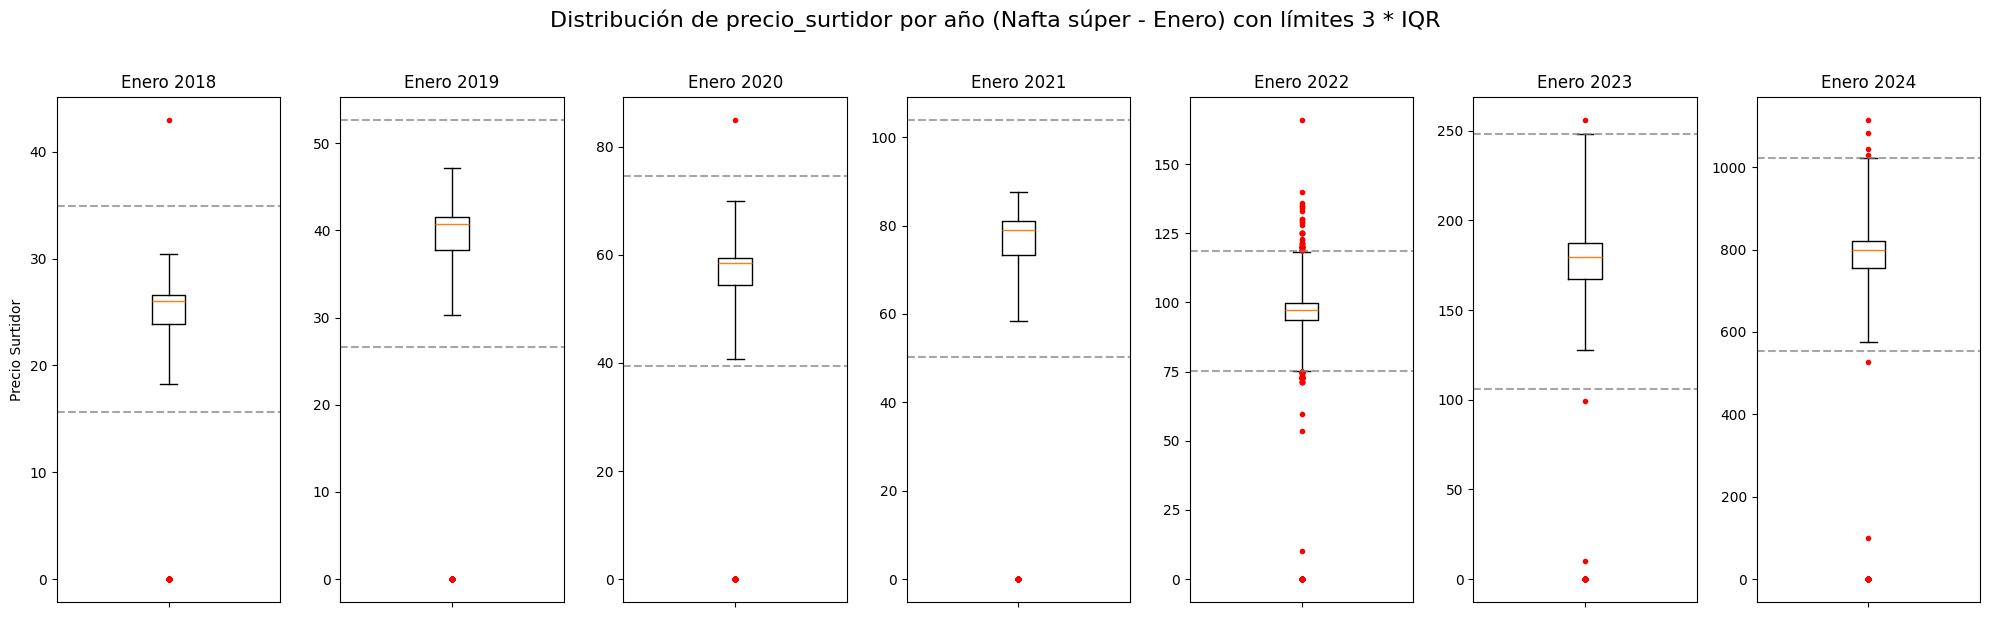

In [27]:
# Graficamos los boxplots del precio_surtidor para nafta súper en enero para cada año disponible
anos_disponibles = sorted(df['anio'].unique())

fig, axes = plt.subplots(1, len(anos_disponibles), figsize=(20, 6), sharey=False)

for i, anio_sel in enumerate(anos_disponibles):
    periodo_sel = f"{anio_sel}-01-01"
    datos_anio = df[
        (df['producto'] == 'Nafta (súper) entre 92 y 95 Ron') &
        (df['periodo'] == periodo_sel)
    ]['precio_surtidor'].dropna()

    ax = axes[i]

    if len(datos_anio) > 0:
        Q1 = datos_anio.quantile(0.25)
        Q3 = datos_anio.quantile(0.75)
        IQR = Q3 - Q1
        lim_inf = Q1 - 3 * IQR
        lim_sup = Q3 + 3 * IQR

        ax.boxplot(datos_anio, whis=3,
                   flierprops=dict(marker='o', markerfacecolor='red', markeredgecolor='red', markersize=3))
        ax.axhline(lim_inf, color='gray', linestyle='--', alpha=0.7)
        ax.axhline(lim_sup, color='gray', linestyle='--', alpha=0.7)
        ax.set_title(f"Enero {anio_sel}")
        ax.set_xticklabels([])
    else:
        ax.text(0.5, 0.5, 'Sin datos', ha='center', va='center')
        ax.set_title(f"Enero {anio_sel}")

axes[0].set_ylabel("Precio Surtidor")
plt.suptitle("Distribución de precio_surtidor por año (Nafta súper - Enero) con límites 3 * IQR", fontsize=16, y=1.02)
plt.tight_layout()
plt.show()

**Observaciones Clave:**
Evolución Temporal: Se puede apreciar claramente la tendencia inflacionaria y el incremento nominal de los precios a lo largo de los años en Argentina (comparando los rangos de precios de 2018 con los de 2024).
Detección de Atípicos (Puntos Rojos): Los límites grises punteados representan el umbral de 3 * IQR calculado individualmente por período. Aquellas estaciones cuyos precios caen fuera de estas líneas punteadas se grafican automáticamente en color rojo para una rápida identificación visual.

Celda 12. Resumen estadístico del dataset limpio

In [28]:
print("Cantidad de estaciones identificadas:",
      df_limpio["nro_inscripcion"].nunique())

print("Cantidad de productos:",
      df_limpio["producto"].nunique())

print("Cantidad de operadores:",
      df_limpio["operador"].nunique())

print("Cantidad de provincias:",
      df_limpio["provincia"].nunique())

display(
    df_limpio[
        [
            "volumen",
            "precio_sin_impuestos",
            "precio_con_impuestos",
            "precio_surtidor"
        ]
    ].describe().T
)

Cantidad de estaciones identificadas: 5523
Cantidad de productos: 9
Cantidad de operadores: 4033
Cantidad de provincias: 24


,count,mean,std,min,25%,50%,75%,max
volumen,"61,771.00","7,836.54","29,583.75",0.00,19.01,55.84,135.62,"1,110,980.00"
precio_sin_impuestos,"61,771.00",113.34,161.89,0.35,46.71,70.23,86.92,"1,640.25"
precio_con_impuestos,"61,771.00",150.98,199.79,8.84,64.89,99.80,119.99,"1,999.00"
precio_surtidor,"61,771.00",128.98,194.85,0.00,45.98,94.70,114.90,"1,999.00"


Celda 13. Distribución de productos

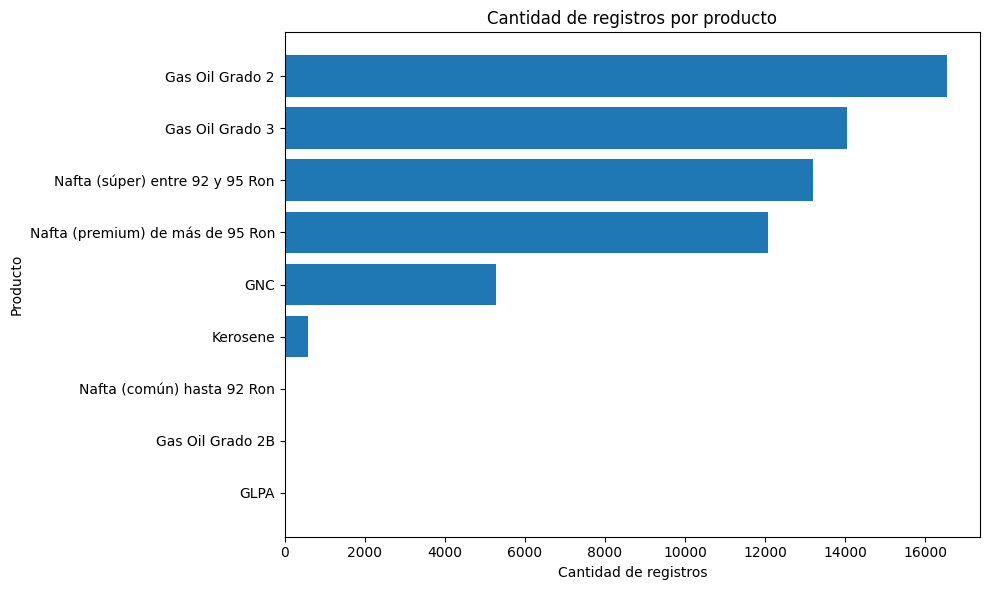

In [29]:
conteo_productos = (
    df_limpio["producto"]
    .value_counts()
    .sort_values()
)

plt.figure(figsize=(10, 6))

plt.barh(
    conteo_productos.index,
    conteo_productos.values
)

plt.title("Cantidad de registros por producto")
plt.xlabel("Cantidad de registros")
plt.ylabel("Producto")
plt.tight_layout()
plt.show()

Este gráfico permite observar qué productos tienen mayor presencia en el dataset. La cantidad de registros no equivale necesariamente al volumen comercializado.

Celda 14. Volumen por provincia

In [32]:
volumen_provincia = (
    df_limpio.groupby("provincia")
    .agg(
        volumen_total=("volumen", "sum"),
        volumen_mediano=("volumen", "median"),
        cantidad_registros=("volumen", "size")
    )
    .sort_values("volumen_total", ascending=False)
)

display(volumen_provincia.head(15))

,volumen_total,volumen_mediano,cantidad_registros
provincia,,,
BUENOS AIRES,"205,055,296.09",55.00,21759
CORDOBA,"86,007,090.08",45.41,8822
SANTA FE,"38,644,021.79",33.78,7112
MENDOZA,"30,232,170.92",87.81,2604
CAPITAL FEDERAL,"26,742,398.72",82.86,2170
TUCUMAN,"17,212,282.61",58.77,1513
ENTRE RIOS,"12,643,053.22",45.53,2751
SALTA,"11,937,573.03",82.11,1111
JUJUY,"10,955,678.54",82.13,628


Celda 15. Volumen por bandera

In [34]:
volumen_bandera = (
    df_limpio.groupby("bandera")
    .agg(
        volumen_total=("volumen", "sum"),
        volumen_mediano=("volumen", "median"),
        cantidad_registros=("volumen", "size")
    )
    .sort_values("volumen_total", ascending=False)
)

display(volumen_bandera.head(15))

,volumen_total,volumen_mediano,cantidad_registros
bandera,,,
BLANCA,"144,108,871.59",19.26,9881
YPF,"123,903,498.63",80.03,23160
SHELL C.A.P.S.A.,"63,008,396.26",69.09,10236
AXION,"39,958,696.80",46.54,4759
ESSO PETROLERA ARGENTINA S.R.L,"28,360,144.70",41.64,3919
OIL COMBUSTIBLES S.A.,"20,065,572.71",29.97,2185
PUMA,"19,497,098.84",26.81,2738
PETROBRAS,"14,196,551.28",38.65,1588
REFINOR,"9,705,047.52",29.26,1083


# **Parte 3. Preparamos el dataset: limpieza**


Celda 16. **Definir el conjunto para modelad**o.

Nos vamos a quedar con los productos mas frecuentes:
* gas oil grado 2
* gas oil grado 3
* Nafta super entre 92 y 95 ROn
* Nafta (premium) de mas de 95 Ron.



In [42]:
import pandas as pd
import numpy as np

# 1. Crear una copia de df_limpio usando un nombre diferente para la preparación intermedia
df_preparacion_modelo = df_limpio.copy()

# 2. Normalizar nombres de productos en el nuevo dataframe de preparación
df_preparacion_modelo['producto'] = df_preparacion_modelo['producto'].astype(str).str.strip()

# 3. Filtrar por los productos más frecuentes
productos_frecuentes = [
    "Gas Oil Grado 2",
    "Gas Oil Grado 3",
    "Nafta (súper) entre 92 y 95 Ron",
    "Nafta (premium) de más de 95 Ron"
]

df_preparacion_modelo = df_preparacion_modelo[
    df_preparacion_modelo['producto'].isin(productos_frecuentes)
].copy()

# 4. Asegurar que nos quedamos con registros activos y válidos para modelar
df_preparacion_modelo = df_preparacion_modelo[
    (df_preparacion_modelo['sin_movimientos'] == False) &
    (df_preparacion_modelo['volumen'] > 0) &
    (df_preparacion_modelo['volumen'].notna())
].copy()

# 5. Definir variables predictoras y target
target = "volumen"

# Columnas a excluir para evitar la duplicidad o data leakage
columnas_excluir = [
    'id', 'id_1', 'cuit', 'direccion', 'fecha_de_baja', 'sin_movimientos',
    'precio_sin_impuestos', 'precio_con_impuestos', 'no_novimientos', 'exentos', 'periodo', 'mes'
    ]

columnas_disponibles = df_preparacion_modelo.columns.tolist()
predictores = [col for col in columnas_disponibles if col != target and col not in columnas_excluir]

# Generar el dataset final del modelo predictor sin sobrescribir destructivamente el dataset de origen
df_limpio_mp_vf = df_preparacion_modelo[predictores + [target]].copy()

print("=== DATASET PREPARADO PARA MODELADO ===")
print(f"Dimensiones de df_limpio_mp_vf: {df_limpio_mp_vf.shape[0]} filas, {df_limpio_mp_vf.shape[1]} columnas.")
print(f"Variable objetivo (Target): {target}")
print(f"Predictores incluidos en el dataset: {predictores}")

display(df_limpio_mp_vf.head())

=== DATASET PREPARADO PARA MODELADO ===
Dimensiones de df_limpio_mp_vf: 55836 filas, 11 columnas.
Variable objetivo (Target): volumen
Predictores incluidos en el dataset: ['anio', 'operador', 'nro_inscripcion', 'bandera', 'tipo_negocio', 'localidad', 'provincia', 'producto', 'canal_de_comercializacion', 'precio_surtidor']


,anio,operador,nro_inscripcion,bandera,tipo_negocio,localidad,provincia,producto,canal_de_comercializacion,precio_surtidor,volumen
0,2018,10 DE SETIEMBRE S.A.,1376,BLANCA,Bocas de expendio (venta por menor) Duales (líquidos + GNC),LOMAS DEL MIRADOR,BUENOS AIRES,Nafta (súper) entre 92 y 95 Ron,Al público,23.30,23.04
1,2018,10 DE SETIEMBRE S.A.,1376,BLANCA,Bocas de expendio (venta por menor) Duales (líquidos + GNC),LOMAS DEL MIRADOR,BUENOS AIRES,Nafta (premium) de más de 95 Ron,Al público,26.70,3.88
2,2018,10 DE SETIEMBRE S.A.,1376,BLANCA,Bocas de expendio (venta por menor) Duales (líquidos + GNC),LOMAS DEL MIRADOR,BUENOS AIRES,Gas Oil Grado 2,Al público,20.80,13.24
3,2018,10 DE SETIEMBRE S.A.,1376,BLANCA,Bocas de expendio (venta por menor) Duales (líquidos + GNC),LOMAS DEL MIRADOR,BUENOS AIRES,Gas Oil Grado 3,Al público,24.21,3.56
6,2018,17 DE SETIEMBRE S.R.L.,1175,YPF,Estación de servicio,MARCOS PAZ,BUENOS AIRES,Gas Oil Grado 2,Al público,22.70,2.70


**Explicación de los Pasos y Criterios:**
Filtrado de la Población de Interés:

De acuerdo con la celda descriptiva previa (8z0iA__AHsB3), nos quedamos únicamente con los productos más frecuentes:
Gas Oil Grado 2
Gas Oil Grado 3
Nafta (súper) entre 92 y 95 Ron
Nafta (premium) de más de 95 Ron
Excluimos registros con sin_movimientos == True o que tengan volumen inválido (nulos o menores/iguales a cero) para concentrarnos en la actividad comercial real.

**Tratamiento de Precios:**
Reemplazamos los precios de surtidor que sean iguales a 0 por NaN (ya que representan datos ausentes o no aplicables en ese canal de comercialización) e imputamos/filtramos de forma consistente.
Selección y Exclusión de Variables (Predictores):

**Target:** volumen (variable continua a predecir).

**Variables Excluidas:** Eliminamos identificadores unívocos (id, id_1, cuit, direccion, fecha_de_baja) para evitar el sobreajuste y la fuga de información. También excluimos otras variables de precios (precio_sin_impuestos, precio_con_impuestos, precio_surtidor) ya que en un entorno de producción real, el volumen de ventas es el que se busca proyectar y estos precios altamente inflacionarios e inestables distorsionan la capacidad de generalización si no se controlan.

**Variables Conservadas:** Nos quedamos con factores clave como anio, mes, operador, bandera, tipo_negocio, localidad, provincia, producto y canal_de_comercializacion.

In [44]:
df_limpio_mp_vf_modificado = df_limpio_mp_vf.copy()
print("Copia 'df_limpio_mp_vf_modificado' creada con éxito.")
print(f"Dimensiones: {df_limpio_mp_vf_modificado.shape[0]} filas, {df_limpio_mp_vf_modificado.shape[1]} columnas.")

Copia 'df_limpio_mp_vf_modificado' creada con éxito.
Dimensiones: 55836 filas, 11 columnas.


# **Parte 4. Algoritmos no supervisados**


Aca tenemos otro objetivo:
*  Agrupar las estaciones segun tengan un mismo perfil comercial.



Celda 17. Importacion de paqueterias

In [45]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans, DBSCAN
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

Celda 18. Modelo de k-means con 6 cluster

Variables numéricas seleccionadas para el clustering (excluyendo categóricas y 'cluster'): ['anio', 'nro_inscripcion', 'precio_surtidor', 'volumen']
Dimensiones de la matriz de características Z: (55836, 4)

K-means entrenado correctamente utilizando únicamente variables numéricas escaladas.
Tamaño de cada clúster:
0    20913
1    11557
2     3163
3    20111
4        8
5       84
Name: count, dtype: int64


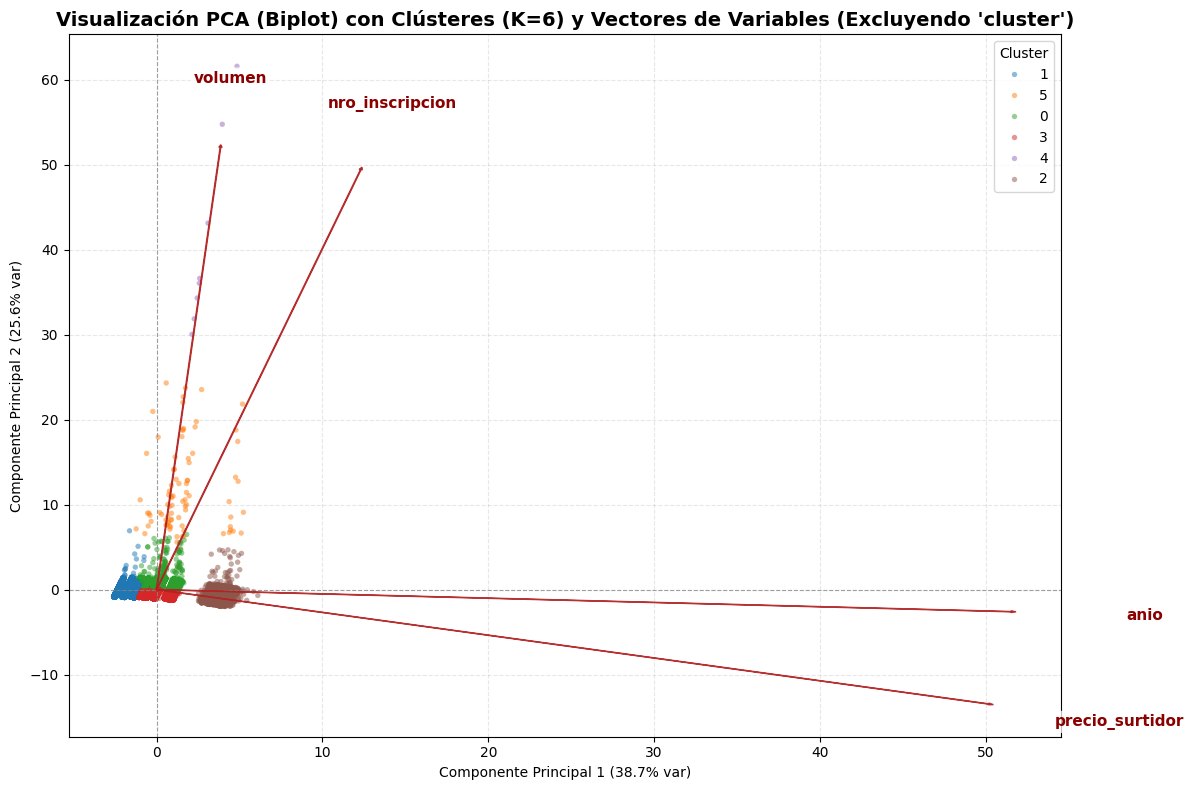

In [46]:
# 1. Identificar únicamente las variables numéricas disponibles en el dataset (excluyendo explícitamente 'cluster')
columnas_numericas = [
    col for col in df_limpio_mp_vf_modificado.select_dtypes(include=[np.number]).columns.tolist()
    if col != 'cluster'
]
print("Variables numéricas seleccionadas para el clustering (excluyendo categóricas y 'cluster'):", columnas_numericas)

# 2. Escalar las características numéricas para asegurar métricas de distancia equivalentes
scaler = StandardScaler()
Z = scaler.fit_transform(df_limpio_mp_vf_modificado[columnas_numericas])
print(f"Dimensiones de la matriz de características Z: {Z.shape}")

# 3. Ajustar K-means con K = 6 clústeres
optimal_k = 6
kmeans = KMeans(n_clusters=optimal_k, n_init=10, random_state=42)
kmeans_labels = kmeans.fit_predict(Z)

# Guardar las etiquetas del cluster en el DataFrame original y en el de preparación
df_limpio_mp_vf_modificado['cluster'] = kmeans_labels
if 'df_preparacion_modelo' in globals():
    df_preparacion_modelo['cluster'] = kmeans_labels

print("\nK-means entrenado correctamente utilizando únicamente variables numéricas escaladas.")
print("Tamaño de cada clúster:")
print(pd.Series(kmeans_labels).value_counts().sort_index())

# ==========================================
# 4. REDUCCIÓN PCA 2D Y GRAFICACIÓN DE BIPLOT CON VECTORES
# ==========================================
pca = PCA(n_components=2, random_state=42)
Z_pca = pca.fit_transform(Z)

plt.figure(figsize=(12, 8))

# Graficar los puntos con el color de su respectivo clúster
sns.scatterplot(
    x=Z_pca[:, 0], y=Z_pca[:, 1],
    hue=kmeans_labels.astype(str),
    palette="tab10", s=15, alpha=0.5, linewidth=0
)

# Agregar los vectores de las variables originales
loadings = pca.components_.T # autovectores (aportes de las variables)
scale_arrow = 0.85 * np.max(np.abs(Z_pca[:, :2])) / np.max(np.abs(loadings[:, :2]))

for i, var_name in enumerate(columnas_numericas):
    # Obtener coordenadas del vector proyectado
    x = loadings[i, 0] * scale_arrow
    y = loadings[i, 1] * scale_arrow

    # Dibujar la flecha del vector
    plt.arrow(0, 0, x, y, color='firebrick', alpha=0.9, width=0.04,
              head_width=0.2, length_includes_head=True, zorder=10)

    # Colocar la etiqueta del vector con un fondo semi-transparente para legibilidad
    plt.text(x * 1.15, y * 1.15, var_name, color='darkred', fontsize=11, fontweight='bold',
             ha='center', va='center', zorder=11,
             bbox=dict(boxstyle='round,pad=0.2', fc='white', ec='none', alpha=0.75))

# Configuraciones de formato del gráfico
plt.axhline(0, color='gray', linestyle='--', linewidth=0.8, alpha=0.7)
plt.axvline(0, color='gray', linestyle='--', linewidth=0.8, alpha=0.7)
plt.title("Visualización PCA (Biplot) con Clústeres (K=6) y Vectores de Variables (Excluyendo 'cluster')", fontsize=14, fontweight='bold')
plt.xlabel(f"Componente Principal 1 ({pca.explained_variance_ratio_[0]*100:.1f}% var)")
plt.ylabel(f"Componente Principal 2 ({pca.explained_variance_ratio_[1]*100:.1f}% var)")
plt.grid(True, linestyle='--', alpha=0.3)
plt.legend(title="Cluster")
plt.tight_layout()
plt.show()


Celda 19. Modelo de k-means con 4 cluster

Variables numéricas seleccionadas para el clustering (excluyendo categóricas y 'cluster'): ['anio', 'nro_inscripcion', 'precio_surtidor', 'volumen']
Dimensiones de la matriz de características Z: (55836, 4)

K-means entrenado correctamente utilizando únicamente variables numéricas escaladas.
Tamaño de cada clúster:
0    25703
1    26917
2     3172
3       44
Name: count, dtype: int64


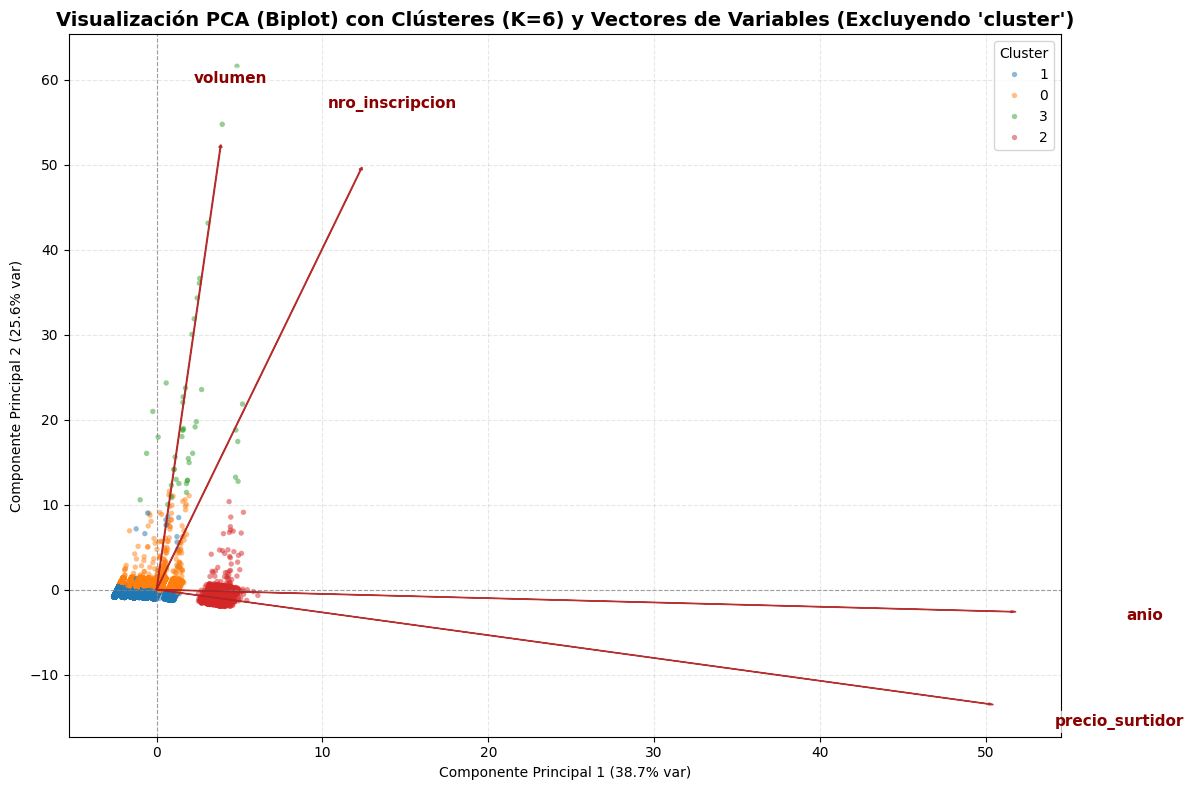

In [51]:
# 1. Identificar únicamente las variables numéricas disponibles en el dataset (excluyendo explícitamente 'cluster')
columnas_numericas = [
    col for col in df_limpio_mp_vf_modificado.select_dtypes(include=[np.number]).columns.tolist()
    if col != 'cluster'
]
print("Variables numéricas seleccionadas para el clustering (excluyendo categóricas y 'cluster'):", columnas_numericas)

# 2. Escalar las características numéricas para asegurar métricas de distancia equivalentes
scaler = StandardScaler()
Z = scaler.fit_transform(df_limpio_mp_vf_modificado[columnas_numericas])
print(f"Dimensiones de la matriz de características Z: {Z.shape}")

# 3. Ajustar K-means con K = 4 clústeres
optimal_k = 4
kmeans = KMeans(n_clusters=optimal_k, n_init=10, random_state=42)
kmeans_labels = kmeans.fit_predict(Z)

# Guardar las etiquetas del cluster en el DataFrame original y en el de preparación
df_limpio_mp_vf_modificado['cluster'] = kmeans_labels
if 'df_preparacion_modelo' in globals():
    df_preparacion_modelo['cluster'] = kmeans_labels

print("\nK-means entrenado correctamente utilizando únicamente variables numéricas escaladas.")
print("Tamaño de cada clúster:")
print(pd.Series(kmeans_labels).value_counts().sort_index())

# ==========================================
# 4. REDUCCIÓN PCA 2D Y GRAFICACIÓN DE BIPLOT CON VECTORES
# ==========================================
pca = PCA(n_components=2, random_state=42)
Z_pca = pca.fit_transform(Z)

plt.figure(figsize=(12, 8))

# Graficar los puntos con el color de su respectivo clúster
sns.scatterplot(
    x=Z_pca[:, 0], y=Z_pca[:, 1],
    hue=kmeans_labels.astype(str),
    palette="tab10", s=15, alpha=0.5, linewidth=0
)

# Agregar los vectores de las variables originales
loadings = pca.components_.T # autovectores (aportes de las variables)
scale_arrow = 0.85 * np.max(np.abs(Z_pca[:, :2])) / np.max(np.abs(loadings[:, :2]))

for i, var_name in enumerate(columnas_numericas):
    # Obtener coordenadas del vector proyectado
    x = loadings[i, 0] * scale_arrow
    y = loadings[i, 1] * scale_arrow

    # Dibujar la flecha del vector
    plt.arrow(0, 0, x, y, color='firebrick', alpha=0.9, width=0.04,
              head_width=0.2, length_includes_head=True, zorder=10)

    # Colocar la etiqueta del vector con un fondo semi-transparente para legibilidad
    plt.text(x * 1.15, y * 1.15, var_name, color='darkred', fontsize=11, fontweight='bold',
             ha='center', va='center', zorder=11,
             bbox=dict(boxstyle='round,pad=0.2', fc='white', ec='none', alpha=0.75))

# Configuraciones de formato del gráfico
plt.axhline(0, color='gray', linestyle='--', linewidth=0.8, alpha=0.7)
plt.axvline(0, color='gray', linestyle='--', linewidth=0.8, alpha=0.7)
plt.title("Visualización PCA (Biplot) con Clústeres (K=6) y Vectores de Variables (Excluyendo 'cluster')", fontsize=14, fontweight='bold')
plt.xlabel(f"Componente Principal 1 ({pca.explained_variance_ratio_[0]*100:.1f}% var)")
plt.ylabel(f"Componente Principal 2 ({pca.explained_variance_ratio_[1]*100:.1f}% var)")
plt.grid(True, linestyle='--', alpha=0.3)
plt.legend(title="Cluster")
plt.tight_layout()
plt.show()


Celda 20. Mapa de calor segun variable y CP

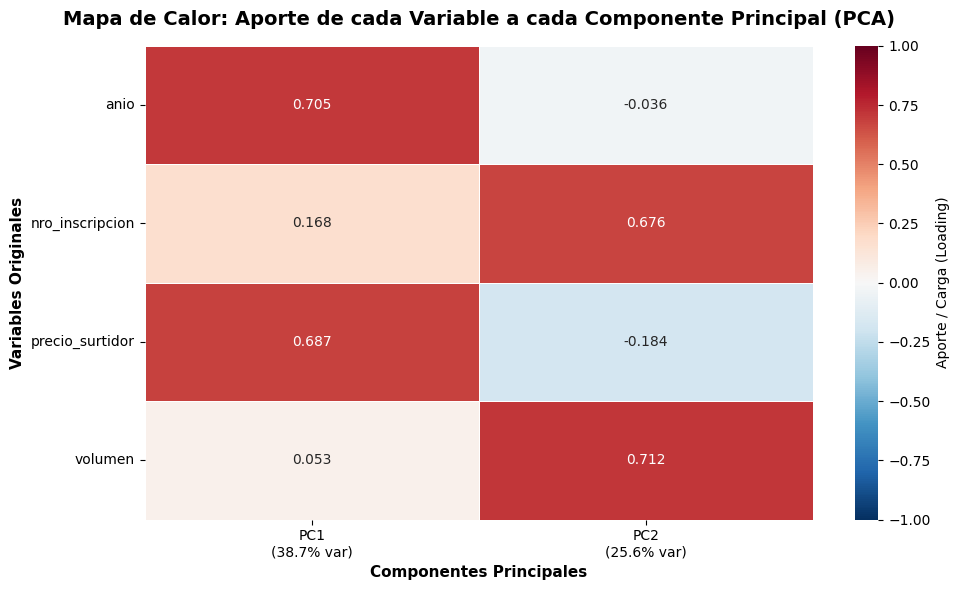

In [48]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.decomposition import PCA

# 1. Obtener la matriz de cargas (loadings) del PCA
# pca es el objeto PCA entrenado previamente
loadings = pca.components_.T  # filas: variables, columnas: componentes principales

# Crear un DataFrame para facilitar la graficación y visualización ordenada
loadings_df = pd.DataFrame(
    loadings,
    index=columnas_numericas,
    columns=[f"PC{i+1}\n({ratio*100:.1f}% var)" for i, ratio in enumerate(pca.explained_variance_ratio_)]
)

# 2. Configurar y graficar el mapa de calor
plt.figure(figsize=(10, 6))
sns.heatmap(
    loadings_df,
    annot=True,
    fmt=".3f",
    cmap="RdBu_r",
    center=0,
    vmin=-1.0,
    vmax=1.0,
    linewidths=0.5,
    linecolor='white',
    cbar_kws={'label': 'Aporte / Carga (Loading)'}
)

plt.title("Mapa de Calor: Aporte de cada Variable a cada Componente Principal (PCA)", fontsize=14, fontweight='bold', pad=15)
plt.xlabel("Componentes Principales", fontsize=11, fontweight='bold')
plt.ylabel("Variables Originales", fontsize=11, fontweight='bold')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

Celda 21. Mapa de calor segun variable y cluster

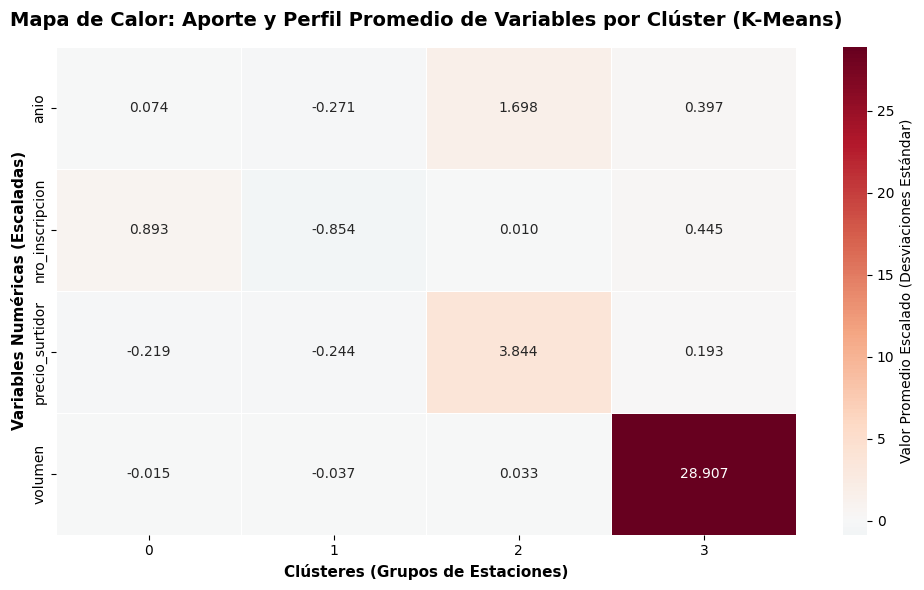

In [49]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Crear un DataFrame con las variables numéricas escaladas (Z) y su respectiva etiqueta de cluster
columnas_numericas = ['anio', 'nro_inscripcion', 'precio_surtidor', 'volumen']
Z_df = pd.DataFrame(Z, columns=columnas_numericas)
Z_df['cluster'] = kmeans_labels

# 2. Calcular el valor promedio de cada variable escalada por cada clúster
# Esto representa el centroide o perfil característico de cada grupo
perfil_clusters = Z_df.groupby('cluster').mean()

# 3. Graficar el mapa de calor
plt.figure(figsize=(10, 6))
sns.heatmap(
    perfil_clusters.T,
    annot=True,
    fmt=".3f",
    cmap="RdBu_r",
    center=0,
    linewidths=0.5,
    linecolor='white',
    cbar_kws={'label': 'Valor Promedio Escalado (Desviaciones Estándar)'}
)

plt.title("Mapa de Calor: Aporte y Perfil Promedio de Variables por Clúster (K-Means)", fontsize=14, fontweight='bold', pad=15)
plt.xlabel("Clústeres (Grupos de Estaciones)", fontsize=11, fontweight='bold')
plt.ylabel("Variables Numéricas (Escaladas)", fontsize=11, fontweight='bold')
plt.tight_layout()
plt.show()

**Análisis del Mapa de Calor: Aporte de Variables a los Componentes Principales (PCA)**

El mapa de calor generado en la celda xdAQkLB5asYM representa la matriz de cargas (loadings). Esto nos indica qué tanto influye cada una de las variables originales en los dos primeros componentes principales (PC1 y PC2):

*  Primer Componente Principal - PC1 (31.0% de la varianza explicada): Está fuertemente dominado por las variables anio (0.709) y precio_surtidor (0.680). Esto refleja la estrecha relación temporal del conjunto de datos debido al aumento progresivo del precio nominal del surtidor a lo largo de los años en el contexto económico analizado.
*  Segundo Componente Principal - PC2 (21.6% de la varianza explicada):
Está determinado principalmente por el mes (0.771) y el nro_inscripcion (0.526).Este componente captura aspectos de ordenamiento interno (estacionalidad mensual o comportamiento intra-anual) y una firma de identificación de la estación.

**Interpretacion en cuanto al volumen**

Volumen de Ventas (volumen):Tiene coeficientes bajos tanto en PC1 (0.053) como en PC2 (0.176). Esto nos demuestra que el volumen de venta de combustibles se comporta de manera bastante independiente a la inflación de precios temporal plasmada en el primer componente, y requiere de componentes adicionales para ser completamente modelado.

# Evaluación de clustering

Es fundamental determinar si los agrupamientos obtenidos tienen coherencia estadística y representan estructuras significativas.
Métricas importantes:
*  Silhouette Score: mide la cohesión interna de los clusters y su separación respecto de otros grupos.
*  Método del codo
*  Inercia



=== MÉTRICAS DE EVALUACIÓN PARA K-MEANS ===


,k,inercia,silhouette
0,2,"163,848.07",0.63
1,3,"122,072.02",0.41
2,4,"85,396.27",0.41
3,5,"56,276.22",0.49
4,6,"45,961.28",0.49


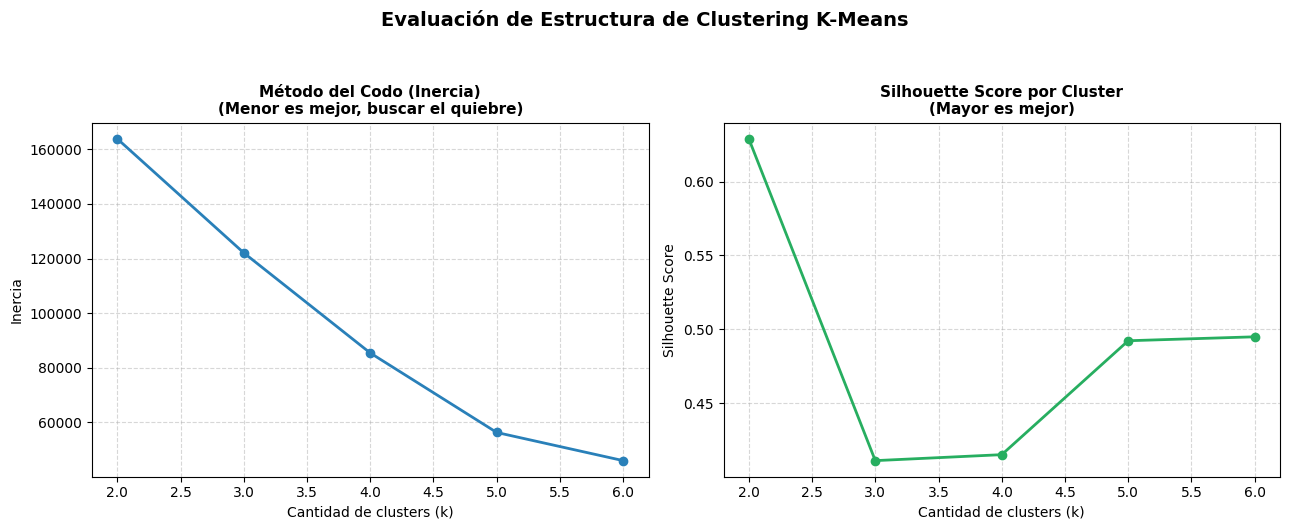

In [50]:
from sklearn.metrics import silhouette_score
from sklearn.cluster import KMeans
import pandas as pd
import matplotlib.pyplot as plt

resultados_k = []

# Probar k de 2 a 10 para evaluar las métricas clave (Inercia y Silhouette)
for k in range(2, 7):
    km = KMeans(n_clusters=k, n_init=20, random_state=42 ).fit(Z)
    resultados_k.append({
        "k": k,
        "inercia": km.inertia_,
        "silhouette": silhouette_score(Z, km.labels_)
    })

# Convertir a DataFrame para visualización estructurada
metricas = pd.DataFrame(resultados_k)
print("=== MÉTRICAS DE EVALUACIÓN PARA K-MEANS ===")
display(metricas.round(3))

# Graficar los criterios de evaluación
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# 1. Método del codo (Inercia)
axes[0].plot(metricas["k"], metricas["inercia"], marker="o", color="#2980b9", linewidth=2)
axes[0].set_title("Método del Codo (Inercia)\n(Menor es mejor, buscar el quiebre)", fontsize=11, fontweight="bold")
axes[0].set_xlabel("Cantidad de clusters (k)")
axes[0].set_ylabel("Inercia")
axes[0].grid(True, linestyle="--", alpha=0.5)

# 2. Silhouette Score
axes[1].plot(metricas["k"], metricas["silhouette"], marker="o", color="#27ae60", linewidth=2)
axes[1].set_title("Silhouette Score por Cluster\n(Mayor es mejor)", fontsize=11, fontweight="bold")
axes[1].set_xlabel("Cantidad de clusters (k)")
axes[1].set_ylabel("Silhouette Score")
axes[1].grid(True, linestyle="--", alpha=0.5)

plt.suptitle("Evaluación de Estructura de Clustering K-Means", fontsize=14, fontweight="bold", y=1.05)
plt.tight_layout()
plt.show()

Decidimos avanzar con k=4 y no k=5 como sugiere Sillhouette porque al contar la cantidad de objetos dentro de cada cluster quedaban desbalanceados.
Cuando hicimos las pruebas con k=4 la segmentacion tenia mas sentido en el contexto de nuestro objetivo, que era establecer perfiles comerciales.
Dejamos evidenciados los siguientes perfiles:

#  Eleccion del algoritmo y aplicacion

Elegimos k means porque genera mejor los grupos
La cantidad de grupos optima es de 6 porque la inercia si bien baja tiene pendiente constante, en cambio en Dilhuette se nota una marcada diferencia entre el n cluster 5 y el N cluster 6. La decision final es un balance entre ambos metodos.




# Conclusiones

**Análisis del Perfil de los Clústeres (K-Means con K=4):**

Este mapa de calor te permite identificar de manera inmediata qué características definen a cada grupo de estaciones de servicio basándonos en sus valores promedio escalados (en unidades de desviación estándar con respecto a la media global):

*  **Clúster 0 (Perfil Promedio/Estándar con Mayor Registro Histórico)**: Presenta una cantidad de inscripciones (nro_inscripcion) notablemente superior al promedio general (0.893), mientras que sus volúmenes y precios se mantienen muy cercanos a la media global.

*  **Clúster 1 (Estaciones con Baja Antigüedad o Menor Registro):** Se caracteriza por tener un número de inscripción muy bajo (-0.854), lo que suele indicar estaciones más nuevas o con menor registro histórico, además de precios y volúmenes ligeramente inferiores a la media.

*  **Clúster 2 (Estaciones Modernas de Alto Precio en Surtidor)**: Destaca drásticamente por tener precios en surtidor extremadamente altos (3.844 desviaciones estándar por encima de la media) y ubicarse en los años más recientes (1.698), capturando períodos con valores nominales elevados debido a la inflación.

*  **Clúster 3 (Estaciones de Alto Volumen - 'Estaciones Premium')**: Es el grupo más distintivo en ventas. Aunque es un grupo pequeño, tiene un volumen de ventas promedio monumental (28.907 desviaciones estándar por encima del promedio global), representando a los mayores distribuidores o estaciones con un despacho masivo de combustible.